# Garbage Classification Model Training

This notebook trains a YOLOv11 model for garbage classification using the Roboflow dataset.

## Step 1: Install Required Libraries

In [ ]:
!pip install roboflow ultralytics opencv-python matplotlib

## Step 2: Download Dataset from Roboflow

In [ ]:
!pip install roboflow

from roboflow import Roboflow

# Initialize Roboflow with your API key
rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
project = rf.workspace("material-identification").project("garbage-classification-3")
version = project.version(1)

# Download dataset in YOLOv11 format
dataset = version.download("yolov11")

print(f"Dataset downloaded to: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...
Dataset downloaded to: /content/GARBAGE-CLASSIFICATION-3-1


## Step 3: Import Required Libraries

In [ ]:
from ultralytics import YOLO
import os
import yaml
from IPython.display import Image, display
import matplotlib.pyplot as plt
import cv2
import numpy as np

## Step 4: Verify Dataset Configuration

In [ ]:
# Check dataset structure
dataset_path = dataset.location
data_yaml_path = os.path.join(dataset_path, 'data.yaml')

# Load and display dataset configuration
with open(data_yaml_path, 'r') as file:
    data_config = yaml.safe_load(file)

print("Dataset Configuration:")
print(f"Training images: {data_config.get('train', 'Not specified')}")
print(f"Validation images: {data_config.get('val', 'Not specified')}")
print(f"Number of classes: {data_config.get('nc', 'Not specified')}")
print(f"Class names: {data_config.get('names', 'Not specified')}")

Dataset Configuration:
Training images: ../train/images
Validation images: ../valid/images
Number of classes: 6
Class names: ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']


## Step 5: Visualize Sample Images from Dataset

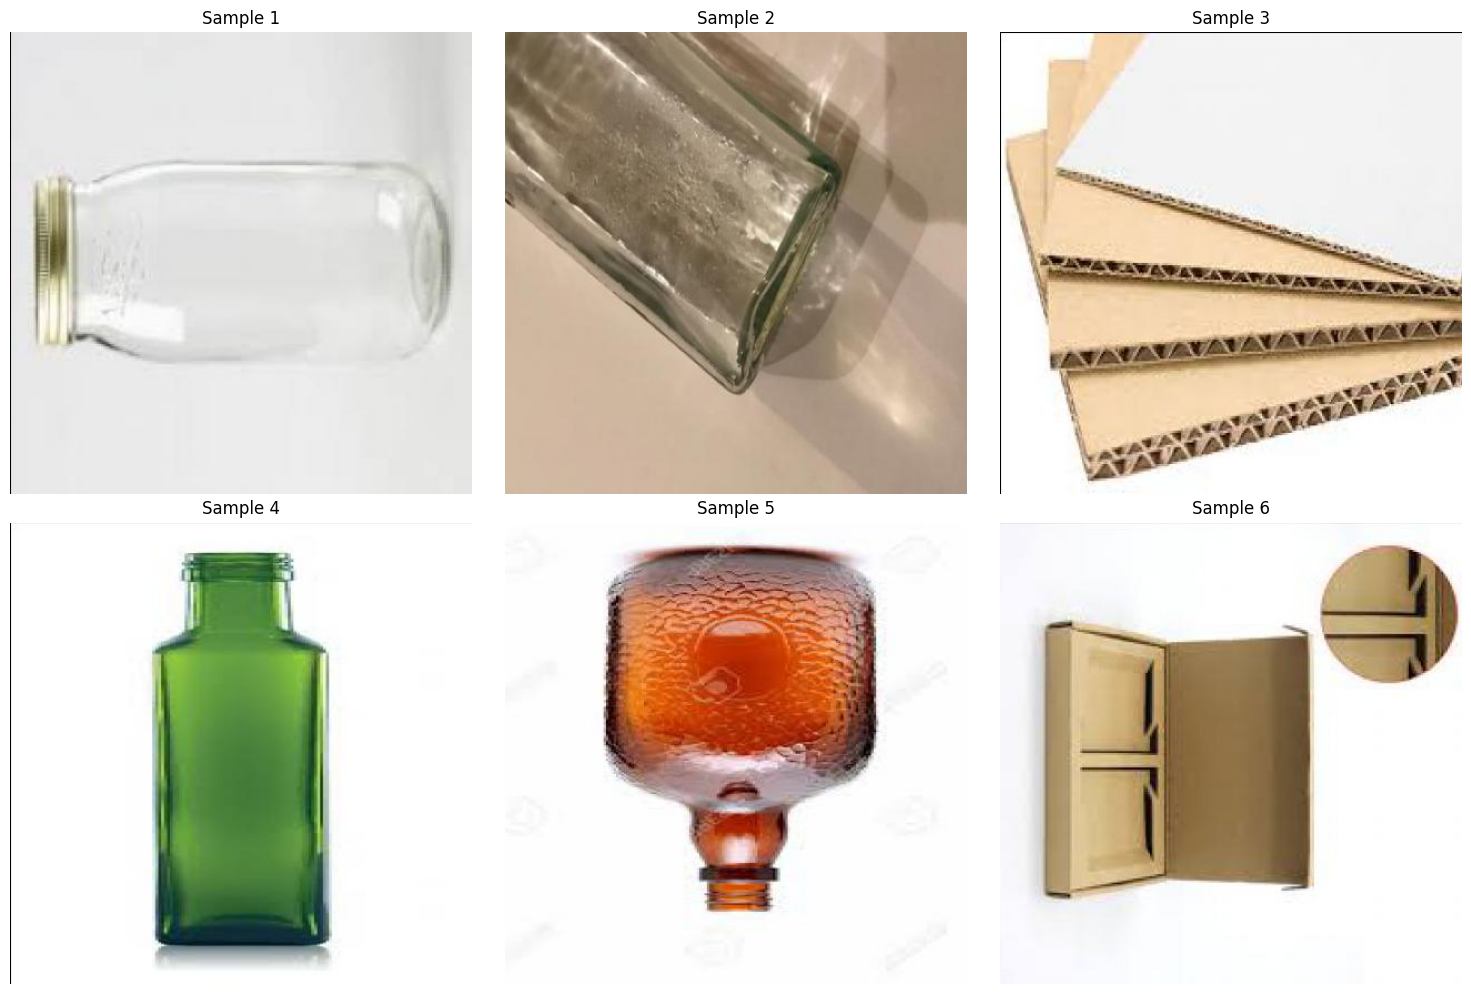

In [ ]:
# Display sample images from training set
train_images_path = os.path.join(dataset_path, 'train', 'images')
sample_images = os.listdir(train_images_path)[:6]  # Get first 6 images

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for idx, img_name in enumerate(sample_images):
    img_path = os.path.join(train_images_path, img_name)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[idx].imshow(img)
    axes[idx].set_title(f'Sample {idx+1}')
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## Step 6: Initialize YOLOv11 Model

We'll use a pre-trained YOLOv11 model as a starting point for transfer learning.

In [ ]:
# Load a pre-trained YOLOv11 model
# Options: yolo11n.pt (nano), yolo11s.pt (small), yolo11m.pt (medium), yolo11l.pt (large), yolo11x.pt (extra large)
model = YOLO('yolo11n.pt')  # Using nano model for faster training

print("Model loaded successfully!")

Model loaded successfully!


## Step 7: Train the Model

Configure training parameters and start training.

In [ ]:
# Train the model
results = model.train(
    data=data_yaml_path,           # Path to dataset YAML file
    epochs=10,                      # Number of training epochs
    imgsz=640,                      # Input image size
    batch=32,                       # Batch size (adjust based on GPU memory)
    name='garbage_classification',  # Experiment name
    patience=10,                    # Early stopping patience
    save=True,                      # Save checkpoints
    device=0,                       # GPU device (use 'cpu' if no GPU available)
    workers=4,                      # Number of workers for data loading
    optimizer='Adam',               # Optimizer
    lr0=0.001,                      # Initial learning rate
    plots=True                      # Generate training plots
)

print("Training completed!")

Ultralytics 8.3.218 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/GARBAGE-CLASSIFICATION-3-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=garbage_classification3, nbs=64, nms=False, opset=None, optimize=False, optimizer=Adam, overlap_mask=True, patience=10, per

## Step 8: Evaluate Model Performance

In [ ]:
# Evaluate the model on the validation set
metrics = model.val()

print("\nValidation Metrics:")
print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")

Ultralytics 8.3.218 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO11n summary (fused): 100 layers, 2,583,322 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 927.8±564.0 MB/s, size: 21.5 KB)
val: Scanning /content/GARBAGE-CLASSIFICATION-3-1/valid/labels.cache... 2098 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2098/2098 4.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 132/132 6.0it/s 22.2s
                   all       2098      18916      0.531      0.423      0.474      0.321
         BIODEGRADABLE        676      13637      0.775      0.463      0.602      0.342
             CARDBOARD        438       1292      0.663      0.448      0.551      0.409
                 GLASS        805       2380      0.807       0.62      0.741       0.55
                 METAL        398       1360       0.59      0.593      0.606      0.394
                 PAPER 


image 1/1 /content/GARBAGE-CLASSIFICATION-3-1/valid/images/glass1451_jpg.rf.2559ac8deff99e80c89c3cc868cc734a.jpg: 640x640 1 GLASS, 1 METAL, 10.0ms
Speed: 2.8ms preprocess, 10.0ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/GARBAGE-CLASSIFICATION-3-1/valid/images/glass3004_jpg.rf.f09338fe6fd05336b5fcd46dc18905d3.jpg: 640x640 1 GLASS, 8.4ms
Speed: 2.3ms preprocess, 8.4ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/GARBAGE-CLASSIFICATION-3-1/valid/images/cardboard1259_jpg.rf.1925a78b92cb1286170f0eae4b3d6e7d.jpg: 640x640 1 CARDBOARD, 8.6ms
Speed: 2.7ms preprocess, 8.6ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/GARBAGE-CLASSIFICATION-3-1/valid/images/glass1920_jpg.rf.cb1e0c13784748af16c088c466feeb38.jpg: 640x640 1 GLASS, 8.7ms
Speed: 2.5ms preprocess, 8.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/GARBAGE-CLASSIFICATION-3-

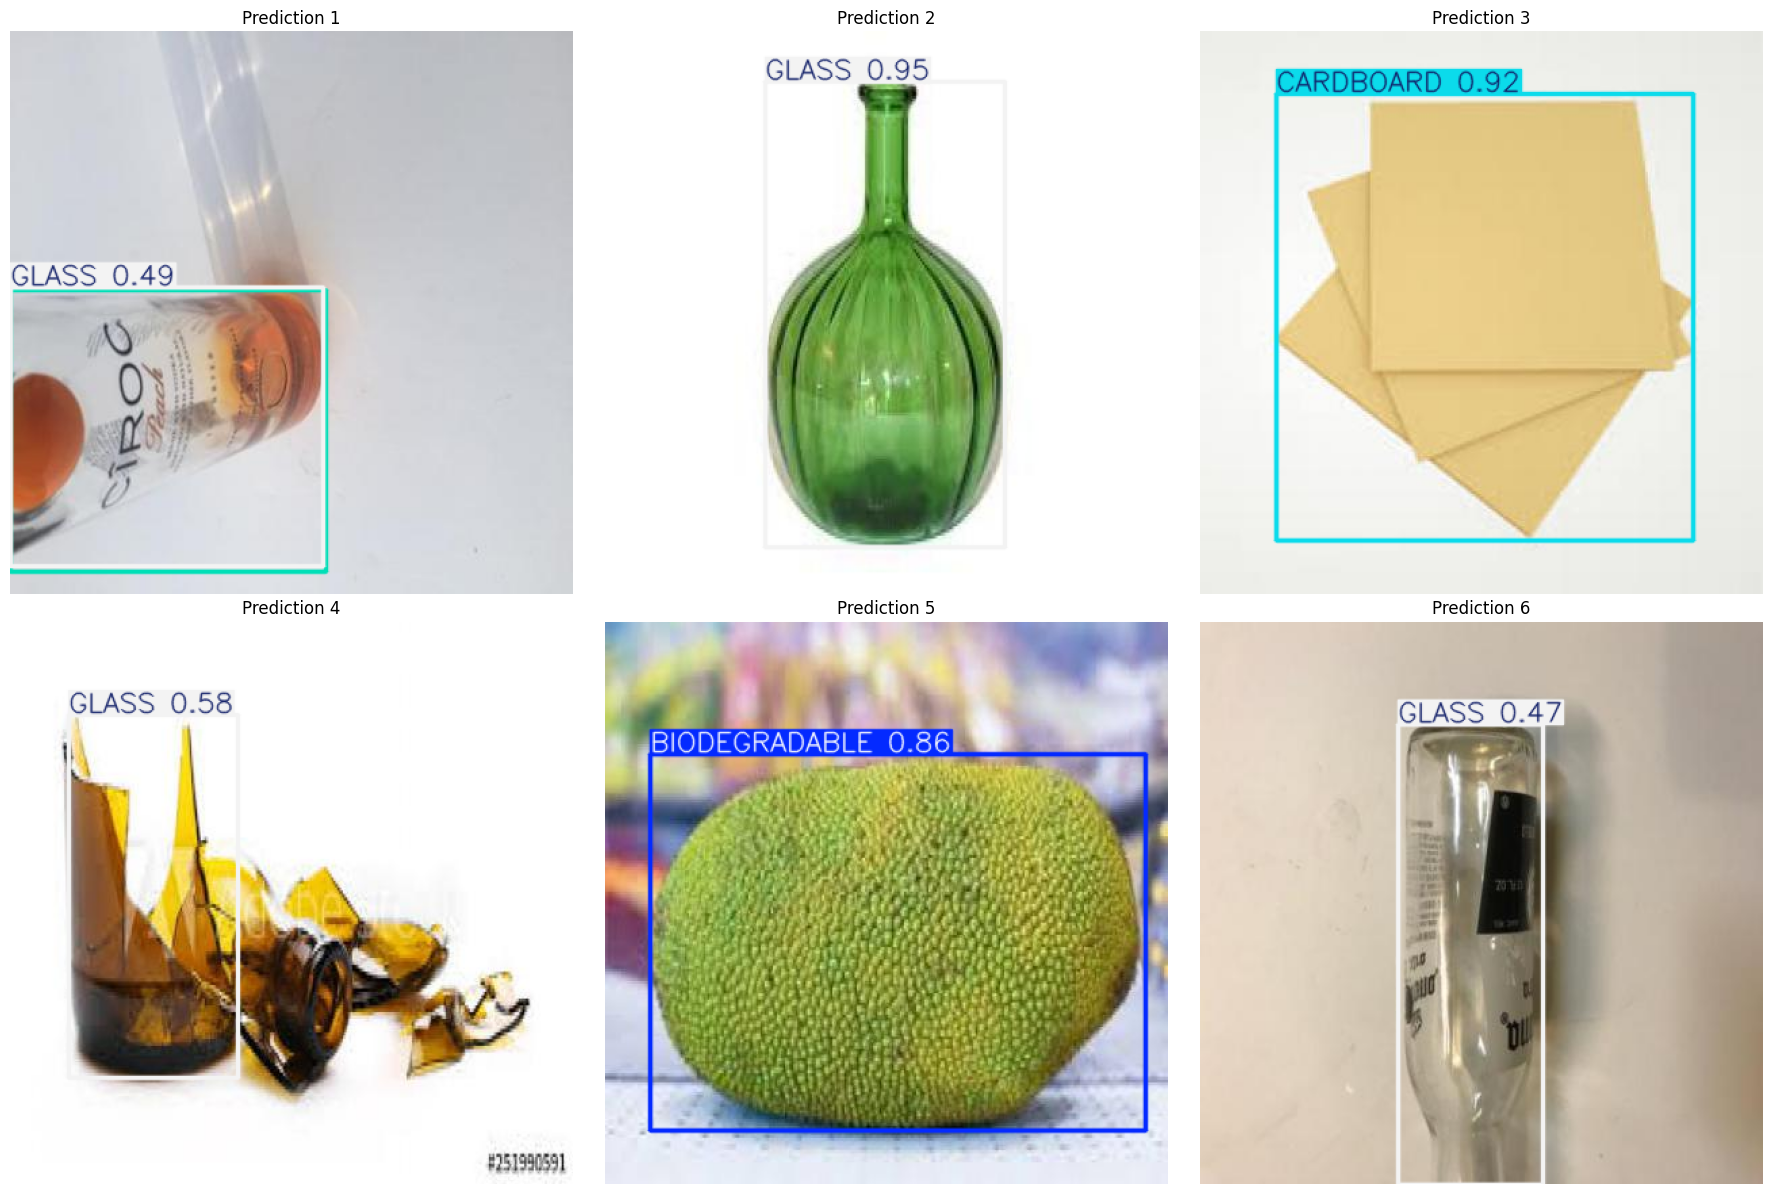

In [ ]:
# Load the best trained model
best_model = YOLO(f'{results_dir}/weights/best.pt')

# Test on validation images
val_images_path = os.path.join(dataset_path, 'valid', 'images')
test_images = os.listdir(val_images_path)[:6]  # Get first 6 validation images

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for idx, img_name in enumerate(test_images):
    img_path = os.path.join(val_images_path, img_name)

    # Run inference
    results = best_model(img_path)

    # Plot results
    result_img = results[0].plot()
    result_img = cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB)

    axes[idx].imshow(result_img)
    axes[idx].set_title(f'Prediction {idx+1}')
    axes[idx].axis('off')

plt.tight_layout()
plt.show()